In [2]:
import reframed
import cobra
import pandas as pd
import numpy as np
from os import listdir
import warnings
import seaborn as sns
from collections import OrderedDict
import json

In [3]:
import sys

sys.path.append("../functions/")
from minimal_medium import minimal_medium

### Find matching identifiers between dataset4 and models

In [4]:
with open('../data/Venturelli2018/generated/metname2metanetx.json') as json_file:
    metname2metanetx = json.load(json_file)

with open("../data/Venturelli2018/generated/metid2metname.json") as json_file:
    metid2metname = json.load(json_file)

In [5]:
dataset4 = pd.read_excel("../data/Venturelli2018/msb178157-sup-0005-datasetev4.xlsx",sheet_name="Dataset EV4",index_col=0)

#### Overlapping idenfiers

In [6]:
mets_compartment_dict = {"c":{},"p":{},"e":{}}


for met_id,met_name in metid2metname.items():
    if "_c_" in met_id:
        mets_compartment_dict["c"][met_name]=met_id
    elif "_p_" in met_id:
        mets_compartment_dict["p"][met_name]=met_id
    elif "_e_" in met_id:
        mets_compartment_dict["e"][met_name]=met_id
                

**Metabolites searched for based on dataset4**

In [7]:
dataset4.shape[0]

97

**Matching metabolites in models**

In [8]:
mets_compartment_df = pd.DataFrame(mets_compartment_dict)
mets_compartment_df.shape[0]

58

**Matching metabolites in compartment 'e'**

In [9]:
mets_compartment_df["e"].dropna().shape[0]

43

In [10]:
mets_compartment_df.fillna("")

,c,p,e
choline_positive_7p50,M_chol__91__c__93__,,
adenosine_positive_6p00,M_adn__91__c__93__,M_adn__91__p__93__,M_adn__91__e__93__
l-aspartate_positive_14p79,M_asp_L__91__c__93__,,M_asp_L__91__e__93__
l-carnitine_positive_10p70,M_crn__91__c__93__,,
cyclic-amp_positive_9p70,M_camp__91__c__93__,,
glycine_betaine_positive_7p75,M_glyb__91__c__93__,M_glyb__91__p__93__,M_glyb__91__e__93__
2deoxyguanosine_positive_8p40,M_dgsn__91__c__93__,M_dgsn__91__p__93__,M_dgsn__91__e__93__
guanine_positive_9p00,M_gsn__91__c__93__,M_gsn__91__p__93__,M_gsn__91__e__93__
l-histidine_positive_13p09,M_his_L__91__c__93__,,M_his_L__91__e__93__
l-serine_positive_13p90,M_ser_L__91__c__93__,M_ser_L__91__p__93__,M_ser_L__91__e__93__


## Creating a media for models based on LB-medium

### Checking growth on LB medium

In [11]:
media_db = pd.read_csv("https://raw.githubusercontent.com/cdanielmachado/carveme/refs/heads/master/carveme/data/input/media_db.tsv",sep="\t")
compounds = media_db[media_db.medium=="LB[-O2]"].compound.values

In [12]:
models = {}
with warnings.catch_warnings():
    warnings.filterwarnings('ignore')
    for path in listdir("../models/species_used/"):
        models[path[:-4]] = reframed.load_cbmodel("../models/species_used/"+path,exchange_detection="R_EX_(?!biomass__40__e__41__)")
    

In [13]:
mets_id_ag = []
mets_id_bigg = []
ex_rxns_ag = []
for model in models.values():
    for rxn in model.get_exchange_reactions():
        if "R_EX_" not in rxn:
            continue
        met_id_ag = model.reactions[rxn].get_substrates()[0]
        mets_id_ag.append(met_id_ag)
        met_id_bigg = model.metabolites[met_id_ag].metadata["XMLAnnotation"].split("bigg.metabolite/")[1].split("\"")[0]
        #met_id_bigg = model.metabolites[met_id_ag].metadata["bigg.metabolite"][0]
        mets_id_bigg.append(met_id_bigg)
        ex_rxns_ag.append(rxn)
    
met2ex = dict(zip(mets_id_bigg,ex_rxns_ag))

In [14]:
for met in compounds:
    if met not in met2ex.keys():
        print(met)

amp
cmp
gmp
lipoate
mobd
ni2
ump


In [15]:
lb_env = reframed.Environment.from_reactions([met2ex[met] for met in compounds if met in met2ex.keys()])

In [48]:
for model_id,model in models.items():
    lb_env.apply(model,inplace=True,exclusive=True,warning=False)
    sol = reframed.FBA(model)
    print(f"{model_id}: {sol.fobj}")

Bacteroides_uniformis_ATCC_8492: 0.6167101596973709
Bacteroides_vulgatus_ATCC_8482: 0.0
Collinsella_aerofaciens_ATCC_25986: 0.0
Faecalibacterium_prausnitzii_A2_165: 0.0
Eggerthella_lenta_DSM_2243: 0.0
Prevotella_copri_CB7_DSM_18205: 0.5233877307380475
Clostridium_hiranonis_TO_931_DSM_13275: 0.0
Eubacterium_rectale_ATCC_33656: 0.9667459103245493
Desulfovibrio_piger_ATCC_29098: 0.0
Bacteroides_ovatus_ATCC_8483: 0.6948093215047774
Bacteroides_thetaiotaomicron_VPI_5482: 0.0
Blautia_hydrogenotrophica_DSM_10507: 0.0


### Defining a media where all members can grow

In [49]:
rxns = ["R_EX_"+met[2:].replace("91","40").replace("93","41") for met in metid2metname.keys() if "__e__" in met]
rxns.append("R_EX_malt__40__e__41__")
rxns.append("R_EX_cellb__40__e__41__")
missing_total = []
specific_solutions = []
sol_count_dfs = {}
for model_id,model in models.items():
    
    lb_env.apply(model,inplace=True,exclusive=True,warning=False)
    sol = reframed.FBA(model)
    print(f"{model_id}: {sol.fobj}")
    
    if sol.fobj>1e-6:
        continue
    
    env_complete = reframed.Environment.complete(model)
    env_complete.apply(model,inplace=True,exclusive=True,warning=False)

    rxns_complete = env_complete.keys()
    rxns_complete = list(set([e for e in rxns_complete if ("R_DM" not in e) and ("_acald_" not in e)])) #("R_DM" not in e) & ("sink" not in e)]
    rxns_complete = [rxn for rxn in rxns_complete if "_o2_" not in rxn]
    
    solutions = minimal_medium(model,exchange_reactions=list(rxns_complete),preferred_reactions=rxns,min_growth=0.1,n_solutions=1000,use_pool=True,min_mass_weight=True)

    print(solutions[1][0])
    sol_count = dict()
    for sol in solutions[0]:
        for rxn in sol:
            if rxn in sol_count.keys():
                sol_count[rxn]+=1
            else:
                sol_count[rxn]=1
    sol_count_df = pd.Series(sol_count).sort_values(ascending=False)
    sol_count_dfs[model_id]=sol_count_df
    
    missing = list((set(sol_count_df[sol_count_df>500].index)-set(lb_env.keys())))
    missing_total.extend(missing)

add2lb = list(set(missing_total))

Bacteroides_uniformis_ATCC_8492: 0.6167101596973709
Bacteroides_vulgatus_ATCC_8482: 0.0


/Users/idunmariaburgos/opt/anaconda3/envs/rcell_rec/lib/python3.8/site-packages/reframed/core/elements.py:62: UserWarning: Atomic weight not listed for elements: {'X'}
  warn(f"Atomic weight not listed for elements: {missing}")


Objective: 344424.11489917577
Status: Unknown

Collinsella_aerofaciens_ATCC_25986: 0.0
Objective: 166468.6285
Status: Unknown

Faecalibacterium_prausnitzii_A2_165: 0.0
Objective: 216376.57879999792
Status: Unknown

Eggerthella_lenta_DSM_2243: 0.0
Objective: 513388.93330000003
Status: Unknown

Prevotella_copri_CB7_DSM_18205: 0.5233877307380475
Clostridium_hiranonis_TO_931_DSM_13275: 0.0
Objective: 137464.23080000002
Status: Unknown

Eubacterium_rectale_ATCC_33656: 0.9667459103245493
Desulfovibrio_piger_ATCC_29098: 0.0
Objective: 102491.0203
Status: Unknown

Bacteroides_ovatus_ATCC_8483: 0.6948093215047774
Bacteroides_thetaiotaomicron_VPI_5482: 0.0
Objective: 212929.89836757525
Status: Unknown

Blautia_hydrogenotrophica_DSM_10507: 0.0
Objective: 196607.2274
Status: Unknown



In [50]:
lb_extended = [met2ex[met] for met in compounds if met in met2ex.keys()]
lb_extended.extend(add2lb)
lb_extended.extend(rxns)

lb_extended = list(set(lb_extended))

env_lb_extend = reframed.Environment.from_reactions(lb_extended)

for model_id,model in models.items():
    env_lb_extend.apply(model,inplace=True,exclusive=True,warning=False)
    sol = reframed.pFBA(model)
    print(f"{model_id}: {sol.values['R_EX_biomass__40__e__41__']}")


Bacteroides_uniformis_ATCC_8492: 2.6734912428231974
Bacteroides_vulgatus_ATCC_8482: 1.7579309271402248
Collinsella_aerofaciens_ATCC_25986: 2.119564729737825
Faecalibacterium_prausnitzii_A2_165: 2.2537638374451006
Eggerthella_lenta_DSM_2243: 0.3940929546124761
Prevotella_copri_CB7_DSM_18205: 2.3251954282262624
Clostridium_hiranonis_TO_931_DSM_13275: 0.7601605197088044
Eubacterium_rectale_ATCC_33656: 3.594250965761282
Desulfovibrio_piger_ATCC_29098: 0.48958790669265295
Bacteroides_ovatus_ATCC_8483: 3.39350647843978
Bacteroides_thetaiotaomicron_VPI_5482: 2.3773806286652714
Blautia_hydrogenotrophica_DSM_10507: 2.8239206162429373


### Plotting minimal media components for models

In [16]:
minimal_media = pd.read_csv("../output/Venturelli2018/minimal_media_lb_extended.tsv",sep="\t",index_col=0)
minimal_media

,Bacteroides_uniformis_ATCC_8492,Bacteroides_vulgatus_ATCC_8482,Collinsella_aerofaciens_ATCC_25986,Faecalibacterium_prausnitzii_A2_165,Eggerthella_lenta_DSM_2243,Prevotella_copri_CB7_DSM_18205,Clostridium_hiranonis_TO_931_DSM_13275,Eubacterium_rectale_ATCC_33656,Desulfovibrio_piger_ATCC_29098,Bacteroides_ovatus_ATCC_8483,Bacteroides_thetaiotaomicron_VPI_5482,Blautia_hydrogenotrophica_DSM_10507
R_EX_k__40__e__41__,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0
R_EX_mn2__40__e__41__,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0
R_EX_fe3__40__e__41__,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0
R_EX_cl__40__e__41__,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0
R_EX_trp_L__40__e__41__,1000.0,0.0,1000.0,1000.0,1000.0,0.0,1000.0,0.0,6.0,93.0,88.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
R_EX_phenol__40__e__41__,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1000.0,0.0,0.0,0.0
R_EX_arab_D__40__e__41__,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1000.0,0.0,0.0,0.0
R_EX_gly__40__e__41__,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,533.0,0.0,0.0,489.0
R_EX_gam26s__40__e__41__,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,290.0,107.0,0.0


In [17]:
minimal_media = minimal_media.loc[(minimal_media.sum(axis=1)!=12000) & (minimal_media.sum(axis=1)>500)]

In [18]:
bigg_met2chebi_class = pd.read_csv("../../../GEMs_from_MAGs/output/met_chebi_class.tsv",sep="\t",index_col=0)

met2chebi = bigg_met2chebi_class["self defined super class"].to_dict()
met2chebi = {key[2:-2]:value for key,value in met2chebi.items()}

agoraEx2chebi = {met2ex[key]: value for key, value in met2chebi.items() if key in met2ex.keys()}

for value in minimal_media.index:
    if value not in agoraEx2chebi.keys():
        agoraEx2chebi[value]="undefined"

pallete = sns.color_palette("tab20b",20)
pallete2 = sns.color_palette("tab20c",20)
pallete.extend([pallete2[-3],pallete2[-1]])

pallete_dict = OrderedDict(zip( list(set(agoraEx2chebi.values())),pallete))

pallete_series = pd.Series({key:pallete_dict[value] for key,value in agoraEx2chebi.items()} )

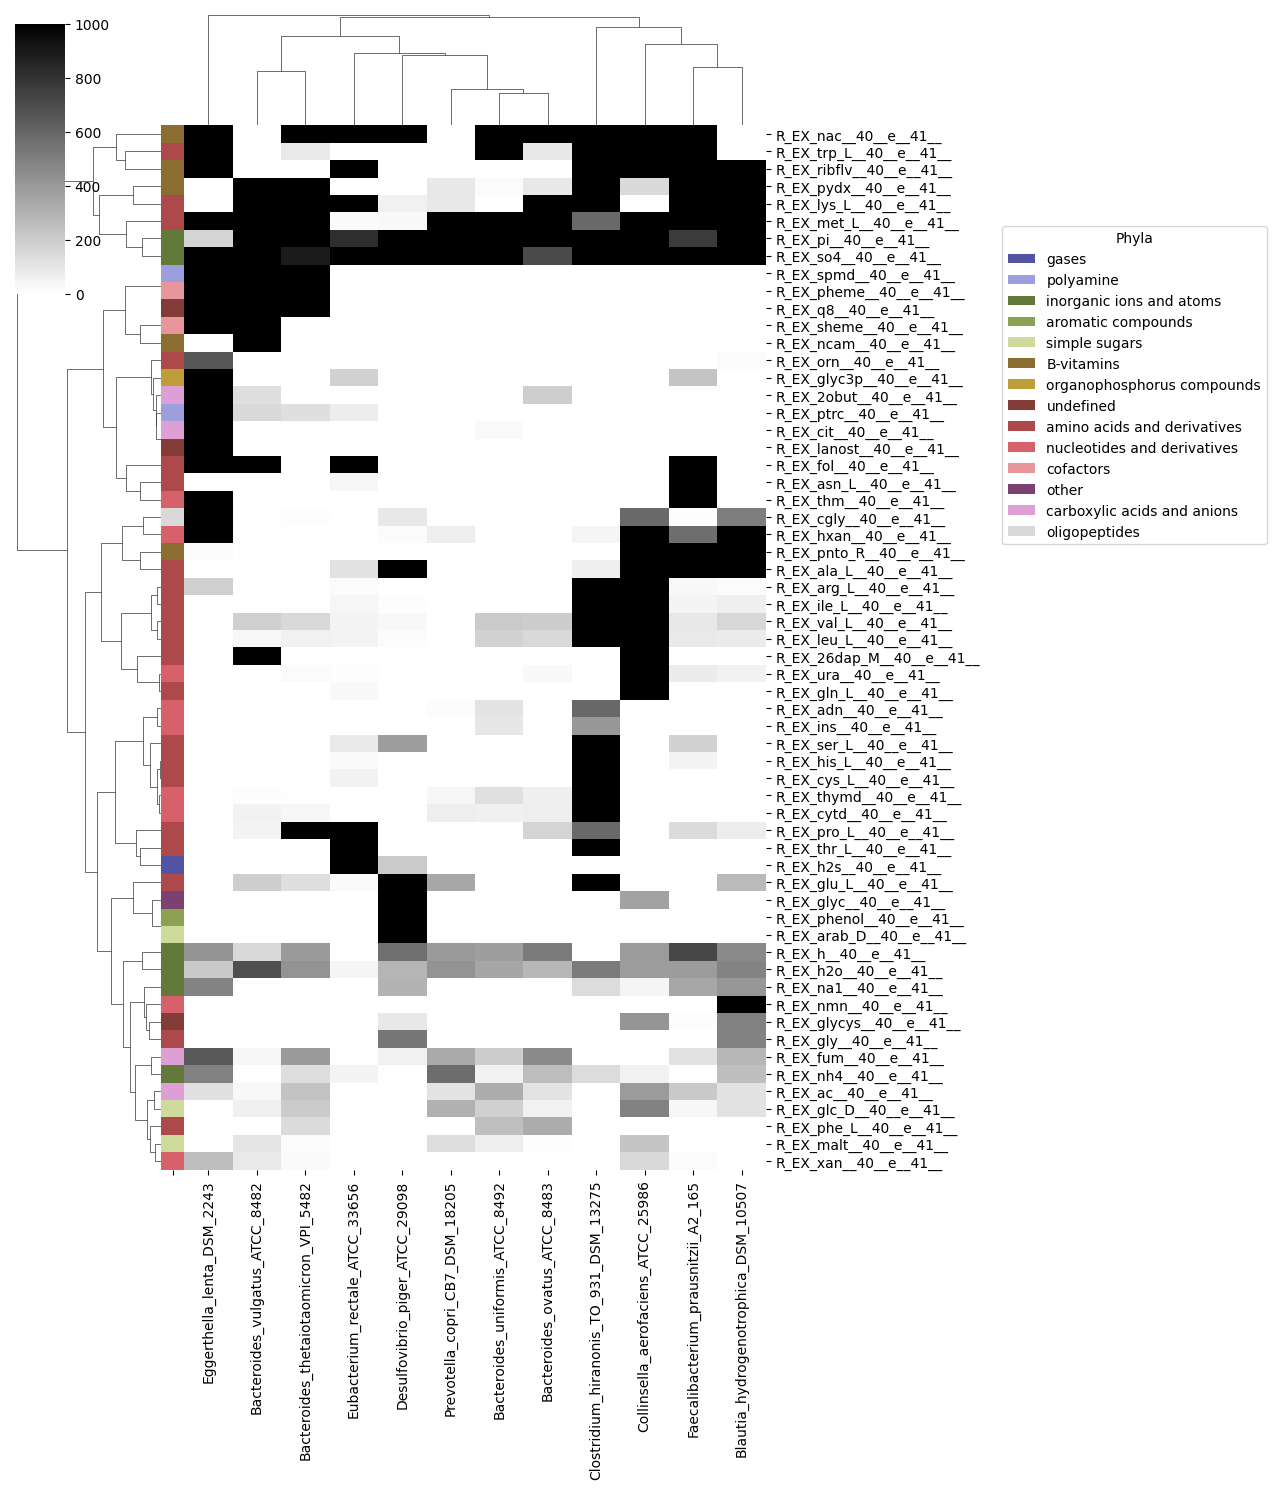

In [19]:
from matplotlib.pyplot import gcf

g = sns.clustermap(minimal_media,figsize=(10,15),cmap="binary",method="ward",vmin=0,fmt="d",dendrogram_ratio=(0.2, 0.1),row_colors=pallete_series)

relevant_classes = list(set([agoraEx2chebi[key] for key in minimal_media.index]))
relevant_classes = [key for key in  pallete_dict.keys() if key in relevant_classes]

for label in relevant_classes:
    g.ax_col_dendrogram.bar(0, 0, color=pallete_dict[label], label=label, linewidth=0)
l1 = g.ax_col_dendrogram.legend(title='Phyla',ncol=1, bbox_to_anchor=(1.0, 0.85), loc='upper left',bbox_transform=gcf().transFigure)




### Make a medium for SteadierCom

In [55]:
lb_extended_copy = lb_extended.copy()
lb_extended_copy = [rxn.replace("40","91") for rxn in lb_extended_copy]
lb_extended_copy = [rxn.replace("41","93") for rxn in lb_extended_copy]
media_db_lb_extend = pd.DataFrame({"medium":["LB_extend" for rxn in lb_extended_copy],
              "compound":lb_extended_copy})

media_db_lb_extend

,medium,compound
0,LB_extend,R_EX_ac__91__e__93__
1,LB_extend,R_EX_ribflv__91__e__93__
2,LB_extend,R_EX_asn_L__91__e__93__
3,LB_extend,R_EX_fum__91__e__93__
4,LB_extend,R_EX_nac__91__e__93__
...,...,...
88,LB_extend,R_EX_so4__91__e__93__
89,LB_extend,R_EX_fe2__91__e__93__
90,LB_extend,R_EX_thr_L__91__e__93__
91,LB_extend,R_EX_cobalt2__91__e__93__


In [56]:
media_db_lb_extend.to_csv("../data/Venturelli2018/generated/media_db_lb_extend.tsv",sep="\t",index=False)

In [57]:
env = reframed.Environment.from_reactions(lb_extended_copy)

#### Remove M_o2__91__e__93__

In [115]:
new_models = {}

for name,model in models.items():
    if "M_o2__91__e__93__" in model.metabolites:
        print(name)
        model.remove_metabolite("M_o2__91__e__93__")
    model.update()
    
    reframed.save_cbmodel(model,"../models/species_used_noO2/"+name+".xml")


### Testing community growth

In [58]:
model1_n2 = reframed.load_cbmodel(f"../models/species_used/Bacteroides_ovatus_ATCC_8483.xml",exchange_detection="R_EX_(?!biomass__40__e__41__)")
model2_n2 = reframed.load_cbmodel(f"../models/species_used/Bacteroides_thetaiotaomicron_VPI_5482.xml",exchange_detection="R_EX_(?!biomass__40__e__41__)")


/Users/idunmariaburgos/opt/anaconda3/envs/rcell_rec/lib/python3.8/site-packages/reframed/io/sbml.py:512: UserWarning: Gene association for reaction R_3OAS100 is not DNF
  warn(f"Gene association for reaction {reaction_id} is not DNF")
/Users/idunmariaburgos/opt/anaconda3/envs/rcell_rec/lib/python3.8/site-packages/reframed/io/sbml.py:512: UserWarning: Gene association for reaction R_3OAS10M11 is not DNF
  warn(f"Gene association for reaction {reaction_id} is not DNF")
/Users/idunmariaburgos/opt/anaconda3/envs/rcell_rec/lib/python3.8/site-packages/reframed/io/sbml.py:512: UserWarning: Gene association for reaction R_3OAS10M12 is not DNF
  warn(f"Gene association for reaction {reaction_id} is not DNF")
/Users/idunmariaburgos/opt/anaconda3/envs/rcell_rec/lib/python3.8/site-packages/reframed/io/sbml.py:512: UserWarning: Gene association for reaction R_3OAS11M12 is not DNF
  warn(f"Gene association for reaction {reaction_id} is not DNF")
/Users/idunmariaburgos/opt/anaconda3/envs/rcell_rec/li

In [59]:
comm_test = reframed.Community("test",[model1_n2,model2_n2],copy_models=True)

env = reframed.Environment.from_reactions(lb_extended_copy)
env.apply(comm_test.merged_model, inplace=True, exclusive=True, warning=False)

sol = reframed.pFBA(comm_test.merged_model)

In [60]:
sol.values["community_growth"]

3.571587445991188

### Complete community - find a minimal medium

In [100]:
sol.values["community_growth"]

21.497570440656997

In [101]:
comm_test = reframed.Community("test",list(models.values()),copy_models=True)


In [102]:
for rxn in comm_test.merged_model.get_metabolite_producers("community_biomass"):
    comm_test.merged_model.reactions[rxn].lb=0.1

In [104]:
comm_test.merged_model.reactions.community_growth.ub=5

In [105]:
env = reframed.Environment.from_reactions(lb_extended_copy)
env.apply(comm_test.merged_model, inplace=True, exclusive=True, warning=False)

sol = reframed.pFBA(comm_test.merged_model)

In [106]:
sol.values["community_growth"]

5.0

In [107]:
sol.show_values("biomass")

R_EX_biomass__40__e__41___M_Bacteroides_uniformis_ATCC_8492  0.1
R_biomass536_M_Bacteroides_uniformis_ATCC_8492  0.1
R_EX_biomass__40__e__41___M_Bacteroides_vulgatus_ATCC_8482  0.1
R_biomass345_M_Bacteroides_vulgatus_ATCC_8482  0.1
R_EX_biomass__40__e__41___M_Collinsella_aerofaciens_ATCC_25986  0.972293
R_biomass524_M_Collinsella_aerofaciens_ATCC_25986  0.972293
R_EX_biomass__40__e__41___M_Faecalibacterium_prausnitzii_A2_165  1.17829
R_biomass223_M_Faecalibacterium_prausnitzii_A2_165  1.17829
R_EX_biomass__40__e__41___M_Eggerthella_lenta_DSM_2243  0.350289
R_biomass467_M_Eggerthella_lenta_DSM_2243  0.350289
R_EX_biomass__40__e__41___M_Prevotella_copri_CB7_DSM_18205  0.1
R_biomass525_M_Prevotella_copri_CB7_DSM_18205  0.1
R_EX_biomass__40__e__41___M_Clostridium_hiranonis_TO_931_DSM_13275  0.313857
R_biomass525_M_Clostridium_hiranonis_TO_931_DSM_13275  0.313857
R_EX_biomass__40__e__41___M_Eubacterium_rectale_ATCC_33656  1.48527
R_biomass205_M_Eubacterium_rectale_ATCC_33656  1.48527
R_EX_b

In [108]:
new_medium_rxns = []
for rxn,value in sol.values.items():
    if rxn.startswith("R_EX_") and value<-1e-6:
        new_medium_rxns.append(rxn)

In [109]:
new_medium_rxns = [rxn.replace("91","40").replace("93","41") for rxn in new_medium_rxns]

In [110]:
set(new_medium_rxns)-set(lb_extended)

set()

In [111]:
set(lb_extended)-set(new_medium_rxns)

{'R_EX_ac__40__e__41__',
 'R_EX_aso3__40__e__41__',
 'R_EX_asp_L__40__e__41__',
 'R_EX_cbl1__40__e__41__',
 'R_EX_cd2__40__e__41__',
 'R_EX_cro4__40__e__41__',
 'R_EX_csn__40__e__41__',
 'R_EX_duri__40__e__41__',
 'R_EX_glyb__40__e__41__',
 'R_EX_h2o__40__e__41__',
 'R_EX_h2s__40__e__41__',
 'R_EX_h__40__e__41__',
 'R_EX_hg2__40__e__41__',
 'R_EX_ins__40__e__41__',
 'R_EX_metsox_S_L__40__e__41__',
 'R_EX_nh4__40__e__41__',
 'R_EX_orn__40__e__41__',
 'R_EX_orot__40__e__41__',
 'R_EX_rbflvrd__40__e__41__',
 'R_EX_so4__40__e__41__',
 'R_EX_taur__40__e__41__',
 'R_EX_thymd__40__e__41__',
 'R_EX_tyr_L__40__e__41__',
 'R_EX_uri__40__e__41__'}

In [ ]:
from steadiercom import 

In [ ]:
comm_test.